<a href="https://colab.research.google.com/github/akatwrk/DeeplearningExp/blob/main/exp_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
(X_train, _), (X_test, _) = mnist.load_data()
print(X_train.shape)
print(X_test.shape)

(60000, 28, 28)
(10000, 28, 28)


In [4]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
X_train = X_train.reshape((-1, 784))
X_test = X_test.reshape((-1, 784))
print(X_train.shape)
print(X_test.shape)

(60000, 784)
(10000, 784)


In [5]:
encoding_dim = 32
input_img = Input(shape=(784,))
encoded = Dense(128, activation="relu")(input_img)
encoded = Dense(64, activation="relu")(encoded)
latent = Dense(encoding_dim, activation="relu")(encoded)
decoded = Dense(64, activation="relu")(latent)
decoded = Dense(128, activation="relu")(decoded)
decoded = Dense(784, activation="sigmoid")(decoded)
autoencoder = Model(input_img, decoded)
encoder = Model(input_img, latent)
autoencoder.compile(
optimizer="adam",
loss="binary_crossentropy"
)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = autoencoder.fit(
X_train,
X_train,
epochs=10,
batch_size=256,
shuffle=True,
validation_data=(X_test, X_test)
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - loss: 0.2445 - val_loss: 0.1651
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.1514 - val_loss: 0.1368
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - loss: 0.1307 - val_loss: 0.1232
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.1212 - val_loss: 0.1162
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1149 - val_loss: 0.1112
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.1103 - val_loss: 0.1067
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.1068 - val_loss: 0.1041
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1044 - val_loss: 0.1026
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1027 - val_loss: 0.1007
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - loss: 0.1013 - val_loss: 0.0997


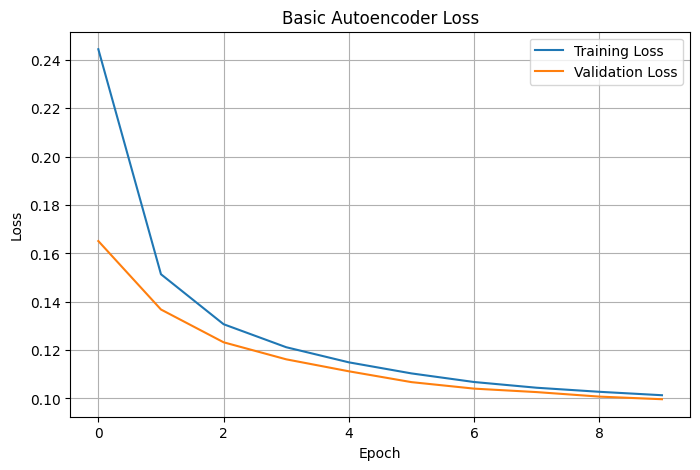

In [7]:
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Basic Autoencoder Loss")
plt.legend()
plt.grid(True)
plt.show()

In [8]:
decoded_imgs = autoencoder.predict(X_test)

latent_features = encoder.predict(X_test)
print("Latent Feature Shape:", latent_features.shape)

print("Original Dimension :",784)
print("Compressed Dimension :",encoding_dim)
print("Compression Ratio :",784/encoding_dim)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Latent Feature Shape: (10000, 32)
Original Dimension : 784
Compressed Dimension : 32
Compression Ratio : 24.5


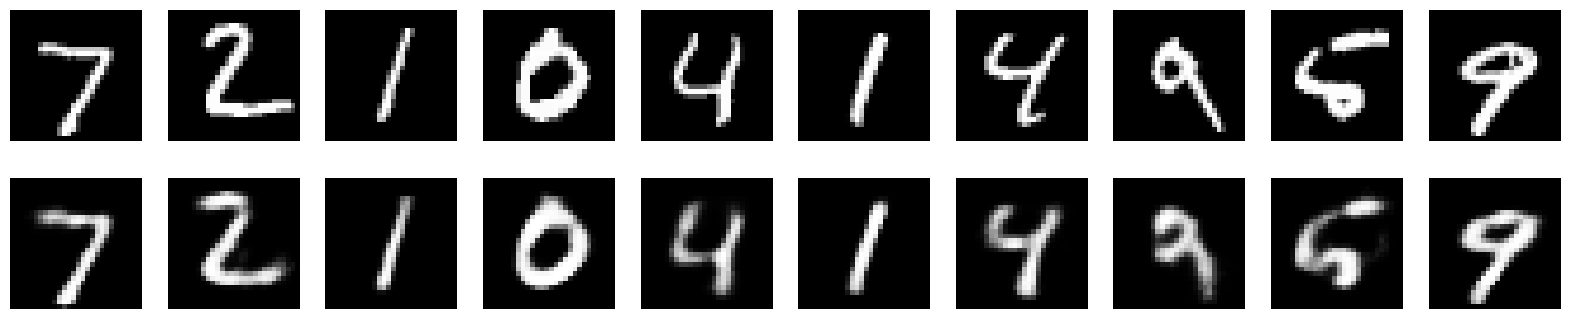

In [9]:
n = 10
plt.figure(figsize=(20,4))
for i in range(n):
    # Original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(X_test[i].reshape(28,28), cmap="gray")
    plt.axis("off")
    # Reconstruction
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28,28), cmap="gray")
    plt.axis("off")
plt.show()

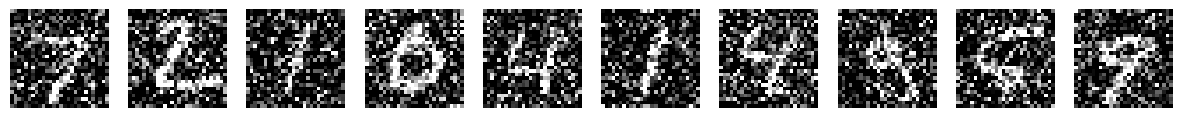

In [10]:
import numpy as np
noise_factor = 0.5
X_train_noisy = X_train + noise_factor * np.random.normal(
loc=0.0,
scale=1.0,
size=X_train.shape
)
X_test_noisy = X_test + noise_factor * np.random.normal(
loc=0.0,
scale=1.0,
size=X_test.shape
)
# Keep pixel values between 0 and 1
X_train_noisy = np.clip(X_train_noisy, 0., 1.)
X_test_noisy = np.clip(X_test_noisy, 0., 1.)
plt.figure(figsize=(15,3))
for i in range(10):
    ax = plt.subplot(1,10,i+1)
    plt.imshow(X_test_noisy[i].reshape(28,28), cmap="gray")
    plt.axis("off")
plt.show()

In [11]:
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
encoding_dim = 32
input_img = Input(shape=(784,))
# Encoder
x = Dense(128, activation="relu")(input_img)
x = Dense(64, activation="relu")(x)
encoded = Dense(encoding_dim, activation="relu")(x)
# Decoder
x = Dense(64, activation="relu")(encoded)
x = Dense(128, activation="relu")(x)
decoded = Dense(784, activation="sigmoid")(x)
dae = Model(input_img, decoded)
dae.compile(
optimizer="adam",
loss="binary_crossentropy"
)
dae.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history_dae = dae.fit(
X_train_noisy,
X_train,
epochs=10,
batch_size=256,
shuffle=True,
validation_data=(X_test_noisy, X_test)
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - loss: 0.2692 - val_loss: 0.2210
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1948 - val_loss: 0.1777
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1710 - val_loss: 0.1631
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.1596 - val_loss: 0.1548
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1524 - val_loss: 0.1482
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1466 - val_loss: 0.1438
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.1430 - val_loss: 0.1411
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1403 - val_loss: 0.1384
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1379 - val_loss: 0.1377
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.1360 - val_loss: 0.1346


In [13]:
decoded_imgs = dae.predict(X_test_noisy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


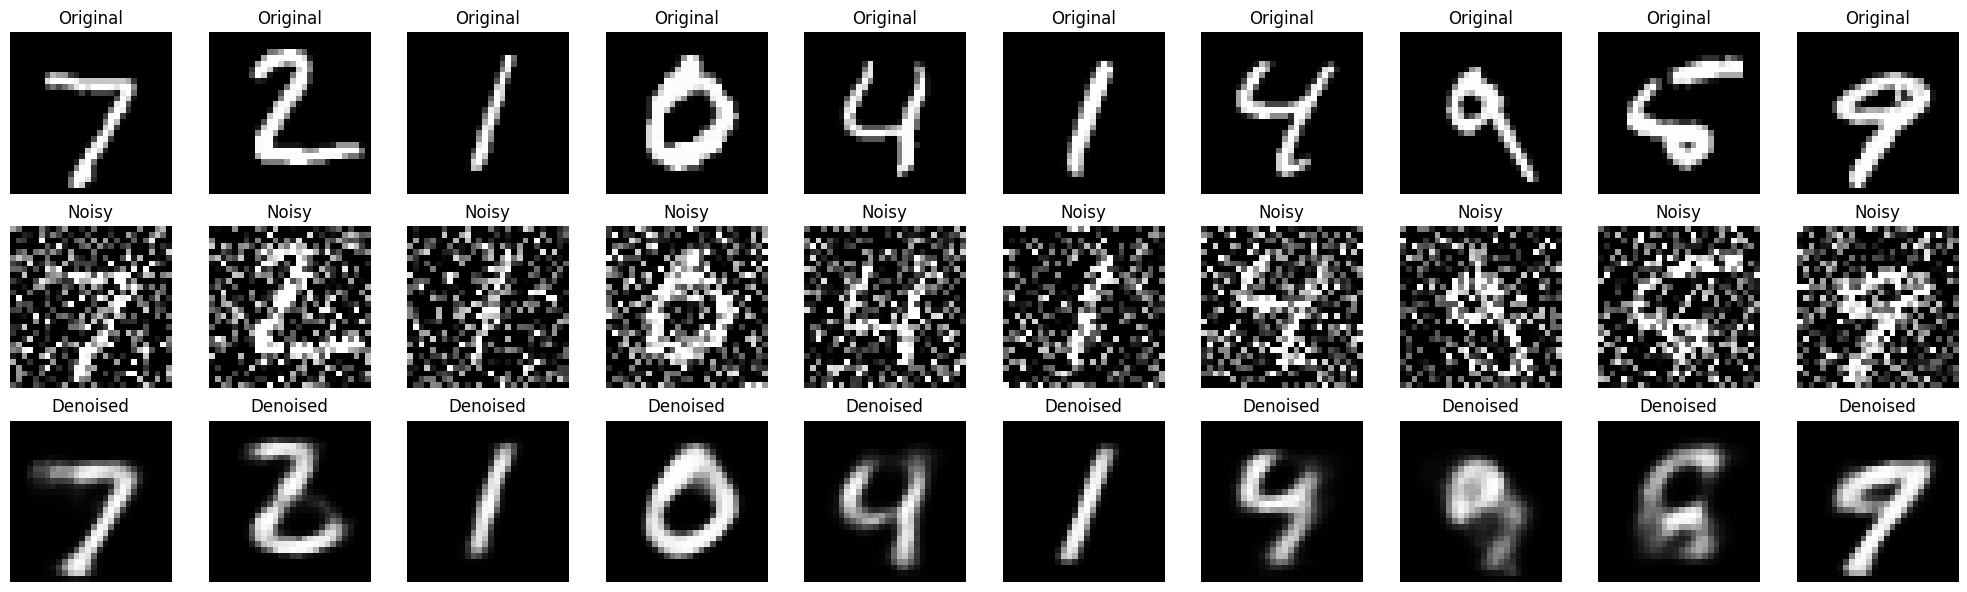

In [14]:
n = 10
plt.figure(figsize=(20,6))
for i in range(n):
    # Original Image
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(X_test[i].reshape(28,28), cmap="gray")
    plt.title("Original")
    plt.axis("off")
    # Noisy Image
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(X_test_noisy[i].reshape(28,28), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")
    # Denoised Image
    ax = plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(decoded_imgs[i].reshape(28,28), cmap="gray")
    plt.title("Denoised")
    plt.axis("off")
plt.tight_layout()
plt.show()

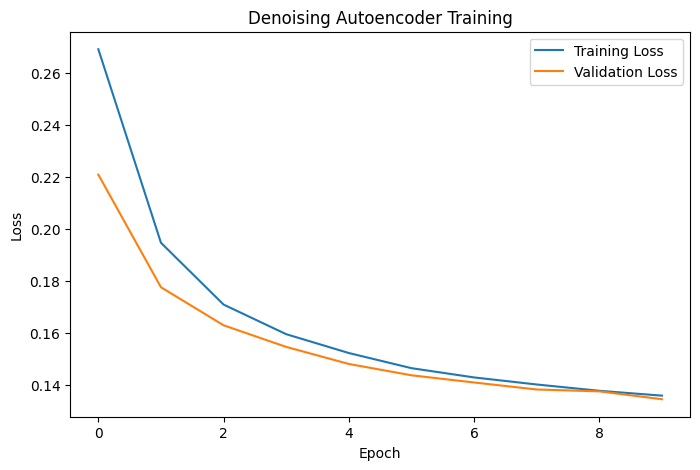

In [15]:
plt.figure(figsize=(8,5))
plt.plot(history_dae.history["loss"], label="Training Loss")
plt.plot(history_dae.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Denoising Autoencoder Training")
plt.legend()
plt.show()


In [19]:
from tensorflow.keras import layers, Model
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
(X_train, _), (X_test, _) = mnist.load_data()
X_train = X_train.astype("float32") / 255.
X_test = X_test.astype("float32") / 255.
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)
input_dim = 784
hidden_dim = 256
latent_dim = 2

# Encoder
inputs = layers.Input(shape=(input_dim,))
x = layers.Dense(hidden_dim, activation="relu")(inputs)
z_mean = layers.Dense(latent_dim)(x)
z_log_var = layers.Dense(latent_dim)(x)

class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

z = Sampling()([z_mean, z_log_var])
encoder = Model(inputs, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

# Decoder
latent_inputs = layers.Input(shape=(latent_dim,))
x = layers.Dense(hidden_dim, activation="relu")(latent_inputs)
outputs = layers.Dense(input_dim, activation="sigmoid")(x)
decoder = Model(latent_inputs, outputs, name="decoder")
decoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 784)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_18 (Dense)    │ (None, 256)       │    200,960 │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_19 (Dense)    │ (None, 2)         │        514 │ dense_18[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_20 (Dense)    │ (None, 2)         │        514 │ dense_18[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling_2          │ (None, 2)         │          0 │ dense_19[0][0],   │
│ (Sampling)          │                   │            │ dense_20[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 201,988 (789.02 KB)

 Trainable params: 201,988 (789.02 KB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 256)            │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 202,256 (790.06 KB)

 Trainable params: 202,256 (790.06 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
class VAE(Model):

    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def train_step(self, data):

        with tf.GradientTape() as tape:

            # Encode
            z_mean, z_log_var, z = self.encoder(data)

            # Decode
            reconstruction = self.decoder(z)

            # Reconstruction Loss
            reconstruction_loss = tf.reduce_mean(
                tf.keras.losses.binary_crossentropy(
                    data,
                    reconstruction
                )
            ) * input_dim
            kl_loss = -0.5 * tf.reduce_mean(
                1 + z_log_var
                - tf.square(z_mean)
                - tf.exp(z_log_var)
            )

            # Total Loss
            total_loss = reconstruction_loss + kl_loss

        grads = tape.gradient(
            total_loss,
            self.trainable_weights
        )

        self.optimizer.apply_gradients(
            zip(grads, self.trainable_weights)
        )

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss
        }
vae = VAE(encoder, decoder)

vae.compile(optimizer="adam")

history = vae.fit(
    X_train,
    epochs=10,
    batch_size=256
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - kl_loss: 4.6388 - loss: 187.7933 - reconstruction_loss: 183.1544
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - kl_loss: 4.1692 - loss: 169.7391 - reconstruction_loss: 165.5698
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - kl_loss: 2.9825 - loss: 175.6786 - reconstruction_loss: 172.6960
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - kl_loss: 3.1042 - loss: 178.9586 - reconstruction_loss: 175.8545
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - kl_loss: 3.2676 - loss: 164.9007 - reconstruction_loss: 161.6330
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - kl_loss: 2.9167 - loss: 171.1560 - reconstruction_loss: 168.2393
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - kl_loss: 3.1023 - loss: 170.3096 - reconstruction_loss: 167.2073
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - kl_loss: 3.3360 - loss: 157.7268 - reconstruction_loss: 154.3908
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 

In [21]:
random_vector = tf.random.normal(shape=(10, latent_dim))
generated = decoder.predict(random_vector)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


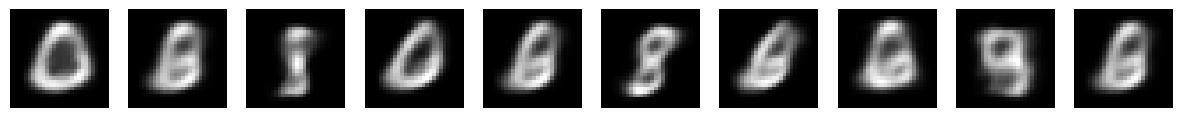

In [22]:
plt.figure(figsize=(15,3))
for i in range(10):
  plt.subplot(1,10,i+1)
  plt.imshow(generated[i].reshape(28,28), cmap="gray")
  plt.axis("off")
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


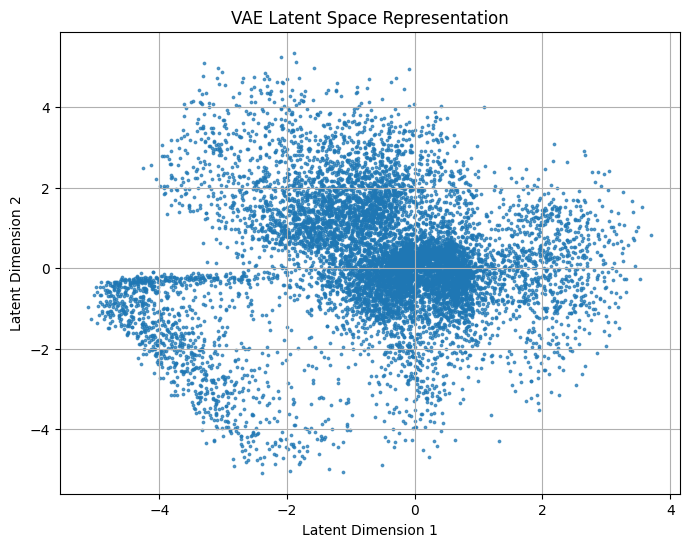

In [25]:
# Get the actual latent representations by running X_test through the encoder
z_mean_val, _, _ = encoder.predict(X_test)

plt.figure(figsize=(8,6))
plt.scatter(z_mean_val[:, 0], z_mean_val[:, 1], s=3, alpha=0.7)
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("VAE Latent Space Representation")
plt.grid(True)
plt.show()

In [27]:
import pandas as pd

comparison = pd.DataFrame({

    "Model":[
        "Basic Autoencoder",
        "Denoising Autoencoder",
        "Variational Autoencoder"
    ],

    "Purpose":[
        "Compression & Feature Extraction",
        "Image Denoising",
        "Image Generation"
    ],

    "Latent Space":[
        "Deterministic",
        "Deterministic",
        "Probabilistic"
    ]

})